# Modelado de PM2.5 — entrega final

## 1. Objetivo

Este notebook construye la tabla de predictores y evalúa los modelos de la entrega final. Responde las dos preguntas de investigación:

1. ¿Puede un modelo de Gradient Boosting, con ventanas de PM2.5 de los días previos y variables de calendario, predecir con un día de anticipación la media diaria de PM2.5 por estación con menor error que la persistencia y anticipar mejor los días en Nivel de Prevención?
2. ¿Cuánto mejora ese pronóstico al añadir la meteorología observada de SIATA, y qué variables explican sus predicciones según SHAP?

Esta primera versión cubre la tabla de predictores y el desempeño de la persistencia, la línea base que todo modelo debe superar. Requiere haber ejecutado los pasos de puesta en marcha del README (descargas y `scripts/build_meteo_hourly.py`).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_pm25_files
from src.data.stations import PM25_TO_METEO
from src.features import CALENDAR_FEATURES, METEO_FEATURES, PM25_FEATURES, TARGET, build_features
from src.models import (
    PREVENTION_THRESHOLD,
    regression_metrics,
    rolling_origin_predictions,
    threshold_for_budget,
    warning_metrics,
)

DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'pm25'
METEO_HOURLY = PROJECT_ROOT / 'data' / 'interim' / 'meteo_hourly.csv'
TEST_YEARS = [2022, 2023, 2024, 2025]

## 2. Carga

Se usan las mismas 16 estaciones y la misma ventana que en el EDA (2018–2025). La carga empieza el 25 de diciembre de 2017 solo para que los rezagos de los primeros días de 2018 tengan datos; esos días previos se descartan después. La meteorología es la tabla horaria construida por `scripts/build_meteo_hourly.py`, que ya descarta los minutos marcados como dudosos y exige 45 minutos válidos por hora.

In [2]:
LOAD_START, WINDOW_START, WINDOW_END = '2017-12-25', '2018-01-01', '2025-12-31'

pm25_wide = load_pm25_files(DATA_DIR)
pm25_wide = pm25_wide[pm25_wide['fecha_hora'].between(LOAD_START, f'{WINDOW_END} 23:00')]
pm25_hourly = pm25_wide.melt(
    id_vars='fecha_hora', value_vars=list(PM25_TO_METEO), var_name='station_id', value_name='pm25'
)
meteo_hourly = pd.read_csv(METEO_HOURLY, parse_dates=['fecha_hora'])

print('PM2.5 horario (estación-hora):', pm25_hourly.shape)
print('Meteorología horaria:', meteo_hourly.shape)
print('Horas con presión de 0 hPa:', int((meteo_hourly['pr'] == 0).sum()))

PM2.5 horario (estación-hora): (1124736, 3)
Meteorología horaria: (801839, 16)
Horas con presión de 0 hPa: 7


La bandera de calidad de SIATA no marca las 7 horas con presión de 0 hPa detectadas en el EDA. Una presión de 0 hPa no es física (en el valle ronda 840 hPa), así que `build_features` las trata como faltantes antes de calcular la media diaria. Era un pendiente abierto desde la Entrega 1.

## 3. Tabla de predictores

Cada fila es una **estación en un día `d`**. Todo predictor usa información observada hasta el final del día `d`; el target es la media del día `d + 1`. La construcción está en `src/features/build_features.py` y sus pruebas en `tests/test_build_features.py`, que incluyen una que verifica que cambiar cualquier dato del día `d + 1` solo cambia el target.

| Grupo | Predictores | Qué representan |
| --- | --- | --- |
| PM2.5 de hoy | `pm25_mean`, `pm25_max`, `pm25_evening_mean` | Media del día (≥18 h válidas), máximo horario y media de 18:00 a 23:00 (≥4 h), la parte del día más cercana a mañana. |
| Ventanas de tiempo | `pm25_lag1` … `pm25_lag6` | Media diaria de 1 a 6 días antes. Con `pm25_mean` cubren la última semana. |
| Ventanas móviles | `pm25_roll3_mean`, `pm25_roll7_mean`, `pm25_roll7_std`, `pm25_diff1` | Nivel y variabilidad de los últimos 3 y 7 días, y cambio respecto a ayer. |
| Meteorología del día | `t`, `h`, `pr`, `vv`, `vv_max`, `p`, `p_sum3` | Temperatura, humedad, presión y viento medios; ráfaga máxima; lluvia del día y de los últimos 3 días (entrada que usó Baena-Salazar et al.). |
| Calendario de mañana | `target_month`, `target_day_of_week` | Mes y día de la semana del día pronosticado, que se conocen de antemano. |

Las ventanas móviles admiten algunos días faltantes (2 de 3 y 5 de 7); los rezagos y la lluvia de 3 días no. No se imputa nada.

In [3]:
features = build_features(pm25_hourly, meteo_hourly, PM25_TO_METEO, LOAD_START, WINDOW_END)
features = features[features['date'] >= WINDOW_START].reset_index(drop=True)
supervised = features.dropna(subset=['pm25_mean', TARGET]).copy()
supervised['year'] = supervised['date'].dt.year
supervised['station'] = supervised['station_id'].astype('category')
supervised['inicio_episodio'] = (supervised['pm25_mean'] < PREVENTION_THRESHOLD) & (supervised[TARGET] >= PREVENTION_THRESHOLD)

print('Tabla estación-día:', features.shape)
print('Con media de hoy:', int(features['pm25_mean'].notna().sum()))
print('Tabla supervisada (media de hoy y target):', len(supervised))
display(supervised.head())

Tabla estación-día: (46752, 27)
Con media de hoy: 45152
Tabla supervisada (media de hoy y target): 44399


,station_id,date,codigo,valid_hours,pm25_mean,pm25_lag1,pm25_lag2,pm25_lag3,pm25_lag4,pm25_lag5,...,vv,vv_max,p,p_sum3,target_month,target_day_of_week,pm25_mean_d_plus_1,year,station,inicio_episodio
0,BAR-TORR,2018-01-01,82,23,17.831593,10.133717,11.499272,9.370924,12.287847,11.286822,...,1.610556,8.9,10.97,NaN,1,1,13.014660,2018,BAR-TORR,False
1,BAR-TORR,2018-01-02,82,23,13.014660,17.831593,10.133717,11.499272,9.370924,12.287847,...,1.273681,10.6,46.63,NaN,1,2,12.264085,2018,BAR-TORR,False
2,BAR-TORR,2018-01-03,82,23,12.264085,13.014660,17.831593,10.133717,11.499272,9.370924,...,1.534718,17.7,47.25,104.85,1,3,10.933441,2018,BAR-TORR,False
3,BAR-TORR,2018-01-04,82,24,10.933441,12.264085,13.014660,17.831593,10.133717,11.499272,...,2.053194,8.0,1.83,95.71,1,4,16.933715,2018,BAR-TORR,False
4,BAR-TORR,2018-01-05,82,24,16.933715,10.933441,12.264085,13.014660,17.831593,10.133717,...,1.326528,6.7,11.98,61.06,1,5,13.421844,2018,BAR-TORR,False


Las cifras coinciden con el EDA: 46.752 combinaciones estación-día, 45.152 con media diaria y 44.399 con media de hoy y target de mañana. La tabla de predictores no pierde ni añade registros respecto a la caracterización de la Entrega 1.

## 4. Faltantes por predictor

Gradient Boosting de scikit-learn en su versión `HistGradientBoostingRegressor` acepta valores faltantes: en cada división aprende hacia qué rama enviarlos. Por eso se conservan los registros con algún predictor vacío en vez de descartarlos o imputarlos.

In [4]:
missing = supervised[PM25_FEATURES + METEO_FEATURES + CALENDAR_FEATURES].isna().mean().mul(100).round(1)
display(missing.to_frame('faltante_pct').T)
complete_meteo = supervised[METEO_FEATURES].notna().all(axis=1)
print('Registros con toda la meteorología:', int(complete_meteo.sum()), f'({100 * complete_meteo.mean():.1f} %)')

,pm25_mean,pm25_lag1,pm25_lag2,pm25_lag3,pm25_lag4,pm25_lag5,pm25_lag6,pm25_roll3_mean,pm25_roll7_mean,pm25_roll7_std,...,pm25_evening_mean,t,h,pr,vv,vv_max,p,p_sum3,target_month,target_day_of_week
faltante_pct,0.0,1.6,2.3,2.6,2.9,3.0,3.0,0.7,1.5,1.5,...,0.7,7.6,8.2,17.4,10.9,11.3,9.2,11.0,0.0,0.0


Registros con toda la meteorología: 32455 (73.1 %)


Los predictores de PM2.5 tienen a lo sumo 3 % de faltantes: los rezagos solo se pierden cuando algún día previo no alcanzó 18 horas válidas. La meteorología tiene más huecos, sobre todo la presión (17,4 %), por la estación 252 sin presión desde 2019 (asignada a ITA-CJUS y ENV-HOSP). Solo el 73,1 % de los registros tiene toda la meteorología. Es algo menos que los 33.134 del EDA porque ahora se exige también la lluvia de los tres días previos y se descartan las presiones de 0 hPa. Excluir esos registros reduciría la tabla en una cuarta parte, por lo que el modelo los usará con faltantes.

## 5. Línea base: persistencia por año de prueba

La persistencia pronostica que mañana tendrá la misma media que hoy. Se evalúa en cada año de prueba del origen móvil (2022, 2023, 2024 y 2025, según el año del día `d`, como en la Tabla II del paper). Las métricas están en `src/models/evaluation.py`. Además del error se reporta R², porque es la métrica que publicaron Baena-Salazar et al., y el desempeño como aviso de Nivel de Prevención con umbral 38 µg/m³.

In [5]:
rows = []
for year in TEST_YEARS:
    test = supervised[supervised['year'] == year]
    warning = warning_metrics(test[TARGET], test['pm25_mean'], test['inicio_episodio'], PREVENTION_THRESHOLD)
    rows.append({
        'año': year,
        'registros': len(test),
        **regression_metrics(test[TARGET], test['pm25_mean']),
        **{k: warning[k] for k in ['eventos', 'avisos', 'precision', 'recall']},
    })
persistence = pd.DataFrame(rows).set_index('año')
display(persistence.round(3))

,registros,MAE,RMSE,R2,eventos,avisos,precision,recall
año,,,,,,,,
2022,5546,3.610,4.701,0.537,59,58,0.500,0.492
2023,5465,3.362,4.508,0.438,36,37,0.270,0.278
2024,5520,3.560,4.668,0.649,158,159,0.597,0.601
2025,5409,2.950,3.884,0.469,4,5,0.000,0.000


La persistencia comete un error medio de 2,95 a 3,61 µg/m³ según el año. Su R² va de 0,44 a 0,65, muy por debajo del 0,80 que alcanza en el periodo de validación de Baena-Salazar et al. (enero–marzo de 2016, ver `feedback-delivery-01/respuestas.md`). La razón es que el R² depende de cuánto varía la serie en el periodo evaluado: ese trimestre incluyó una contingencia ambiental con grandes cambios de nivel, mientras que un año completo contiene muchos días de concentración moderada. Por eso la comparación con ese estudio debe hacerse en su mismo periodo y no con el R² de nuestra ventana.

Como aviso de Nivel de Prevención, la persistencia acierta alrededor de la mitad de los eventos en 2022 y 2024, años con episodios de varios días, y apenas una cuarta parte en 2023, cuando la mayoría de los eventos son inicios de episodio (26 de 36). En 2025, con solo 4 eventos, no acierta ninguno: no hay suficientes eventos para medir anticipación, lo que confirma que la evaluación debe reportarse año por año y no con un único periodo de prueba.

## 6. Protocolo de evaluación

Se comparan tres pronósticos de la media de mañana:

| Pronóstico | Predictores |
| --- | --- |
| Persistencia | La media de hoy. |
| Gradient Boosting sin meteorología | Estación, PM2.5 (hoy, ventanas y rezagos) y calendario. Responde la pregunta 1. |
| Gradient Boosting con meteorología | Lo anterior más la meteorología del día. La diferencia con el anterior responde la pregunta 2. |

**Origen móvil.** Cada año de 2019 a 2025 se predice con un modelo entrenado solo con los años anteriores (2019 con 2018; 2025 con 2018–2024). Los años 2022 a 2025 son los de prueba; las predicciones de 2019–2021 sirven solo para elegir hiperparámetros y calibrar avisos, sin mirar ningún año de prueba.

**Hiperparámetros.** Se eligieron con el MAE fuera de muestra de 2019–2021. El MAE casi no cambió entre configuraciones (diferencias de centésimas de µg/m³) y las mejores fueron modelos pequeños: árboles de 7 hojas, tasa de aprendizaje 0,03 y 300 iteraciones. Se usa la misma configuración en los dos modelos para que solo cambien los predictores. La estación entra como variable categórica.

In [6]:
GB_PARAMS = dict(learning_rate=0.03, max_iter=300, max_leaf_nodes=7, min_samples_leaf=50, random_state=0)
FEATURES_SIN_METEO = ['station', *PM25_FEATURES, *CALENDAR_FEATURES]
FEATURES_CON_METEO = [*FEATURES_SIN_METEO, *METEO_FEATURES]
PREDICTED_YEARS = range(2019, 2026)


def gradient_boosting(columns):
    def fit_predict(train, test):
        model = HistGradientBoostingRegressor(**GB_PARAMS).fit(train[columns], train[TARGET])
        return model.predict(test[columns])
    return fit_predict


evaluated = supervised[supervised['year'] >= PREDICTED_YEARS[0]]
predictions = pd.DataFrame({
    'persistencia': evaluated['pm25_mean'],
    'GB sin meteo': rolling_origin_predictions(supervised, PREDICTED_YEARS, gradient_boosting(FEATURES_SIN_METEO)),
    'GB con meteo': rolling_origin_predictions(supervised, PREDICTED_YEARS, gradient_boosting(FEATURES_CON_METEO)),
})
MODELS = list(predictions)
print('Predicciones fuera de muestra:', predictions.shape)

Predicciones fuera de muestra: (38922, 3)


## 7. Error de concentración

modelo,persistencia,GB sin meteo,GB con meteo
año,,,
2022,3.610,2.977,2.942
2023,3.362,2.775,2.756
2024,3.560,2.843,2.818
2025,2.950,2.424,2.391
2022–2025,3.373,2.757,2.729


modelo,persistencia,GB sin meteo,GB con meteo
año,,,
2022,0.537,0.684,0.692
2023,0.438,0.619,0.623
2024,0.649,0.771,0.776
2025,0.469,0.655,0.666
2022–2025,0.563,0.709,0.715


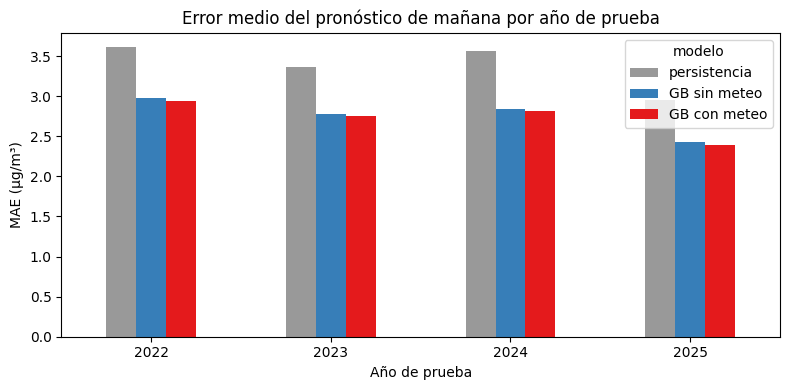

In [7]:
rows = []
for year in [*TEST_YEARS, '2022–2025']:
    mask = evaluated['year'] >= 2022 if year == '2022–2025' else evaluated['year'] == year
    for model in MODELS:
        rows.append({'año': year, 'modelo': model, **regression_metrics(evaluated.loc[mask, TARGET], predictions.loc[mask, model])})
regression = pd.DataFrame(rows).set_index(['año', 'modelo'])
display(regression['MAE'].unstack('modelo')[MODELS].round(3))
display(regression['R2'].unstack('modelo')[MODELS].round(3))

ax = regression['MAE'].unstack('modelo')[MODELS].loc[TEST_YEARS].plot.bar(figsize=(8, 4), rot=0, color=['#999999', '#377eb8', '#e41a1c'])
ax.set(xlabel='Año de prueba', ylabel='MAE (µg/m³)', title='Error medio del pronóstico de mañana por año de prueba')
plt.tight_layout()
plt.show()

Gradient Boosting reduce el error de la persistencia en los cuatro años de prueba. En 2022–2025 el MAE baja de 3,37 a 2,76 µg/m³ sin meteorología (−18 %) y a 2,73 µg/m³ con meteorología. El R² sube de 0,56 a 0,71–0,72. La meteorología mejora el MAE en los cuatro años, pero poco: entre 0,02 y 0,04 µg/m³, alrededor de 1 %, como anticipó la prueba lineal de la Entrega 1.

### 7.1 ¿Las diferencias son reales?

Las diferencias de MAE se estiman con un bootstrap por bloques: se remuestrean bloques de 14 días consecutivos (con todas las estaciones de esos días), para respetar que los errores de días cercanos y de estaciones vecinas están correlacionados. Se reporta el intervalo del 95 % de la diferencia en 2022–2025.

In [8]:
test = evaluated['year'] >= 2022
abs_error = predictions[test].sub(evaluated.loc[test, TARGET], axis=0).abs()
differences = pd.DataFrame({
    'GB sin meteo − persistencia': abs_error['GB sin meteo'] - abs_error['persistencia'],
    'GB con meteo − GB sin meteo': abs_error['GB con meteo'] - abs_error['GB sin meteo'],
})
block = (evaluated.loc[test, 'date'] - evaluated.loc[test, 'date'].min()).dt.days // 14
block_sums, block_counts = differences.groupby(block.to_numpy()).sum(), differences.groupby(block.to_numpy()).count()

rng = np.random.default_rng(0)
draws = []
for _ in range(5000):
    sample = rng.integers(0, len(block_sums), len(block_sums))
    draws.append(block_sums.iloc[sample].sum() / block_counts.iloc[sample].sum())
draws = pd.DataFrame(draws)
display(pd.DataFrame({
    'diferencia_MAE': differences.mean(),
    'IC95_inferior': draws.quantile(0.025),
    'IC95_superior': draws.quantile(0.975),
}).round(3))

by_station = abs_error.groupby(evaluated.loc[test, 'station_id']).mean()
gain = (by_station['GB sin meteo'] - by_station['GB con meteo']).sort_values()
print('Estaciones donde la meteorología reduce el MAE:', int((gain > 0).sum()), 'de', len(gain))
display(gain.round(3).to_frame('reducción_MAE_por_meteo'))

,diferencia_MAE,IC95_inferior,IC95_superior
GB sin meteo − persistencia,-0.617,-0.690,-0.542
GB con meteo − GB sin meteo,-0.028,-0.045,-0.014


Estaciones donde la meteorología reduce el MAE: 16 de 16


,reducción_MAE_por_meteo
station_id,
BEL-FEVE,0.001
ITA-CONC,0.007
MED-VILL,0.007
MED-SCRI,0.007
COP-CVID,0.011
EST-HOSP,0.015
BAR-TORR,0.016
CEN-TRAF,0.017
CAL-JOAR,0.026


Las dos mejoras son reales. Gradient Boosting reduce el MAE de la persistencia en 0,62 µg/m³ (IC 95 %: 0,54 a 0,69). La meteorología lo reduce en 0,028 µg/m³ (IC 95 %: 0,014 a 0,045): es pequeña, pero ninguno de los intervalos incluye el cero y la mejora aparece en las 16 estaciones.

La ganancia por estación coincide con la calidad de la meteorología asignada. Las dos estaciones donde la meteorología casi no aporta son BEL-FEVE (su estación 271 no tiene datos desde agosto de 2024) e ITA-CONC (la 206 no midió viento entre 2019 y 2024). La mayor ganancia está en MED-BEME, ITA-CJUS y MED-ALTA. Esto sugiere que cubrir esos huecos podría aumentar algo el aporte.

## 8. Avisos de Nivel de Prevención

Un pronóstico se convierte en aviso cuando alcanza un umbral. Primero se usa el umbral fijo de 38 µg/m³. Una regresión que minimiza el error medio subestima los picos, así que con ese umbral avisa menos que la persistencia y la comparación queda sesgada a favor de esta (decisión del 2026-09-14 en `docs/decisions.md`).

In [9]:
rows = []
for year in [*TEST_YEARS, '2022–2025']:
    mask = evaluated['year'] >= 2022 if year == '2022–2025' else evaluated['year'] == year
    for model in MODELS:
        rows.append({'año': year, 'modelo': model, **warning_metrics(
            evaluated.loc[mask, TARGET], predictions.loc[mask, model], evaluated.loc[mask, 'inicio_episodio'], PREVENTION_THRESHOLD)})
fixed = pd.DataFrame(rows).set_index(['año', 'modelo'])
display(fixed.loc['2022–2025'].round(3))

,eventos,avisos,precision,recall,inicios,inicios_avisados
modelo,,,,,,
persistencia,257,259,0.517,0.521,123,0
GB sin meteo,257,159,0.642,0.397,123,13
GB con meteo,257,165,0.630,0.405,123,12


Con el umbral fijo de 38 µg/m³, Gradient Boosting avisa mucho menos que la persistencia (159–165 avisos frente a 259 en 2022–2025): es más preciso (0,63–0,64 frente a 0,52) pero detecta menos eventos (recall 0,40–0,41 frente a 0,52). Aun así anticipa 12–13 inicios de episodio, que la persistencia con ese umbral no puede anticipar nunca. Como cada método avisa un número distinto de veces, esta tabla no permite decir cuál es mejor.

### 8.1 Comparación a igual número de avisos

Para comparar con justicia, cada método recibe el mismo presupuesto de avisos: su umbral se fija de modo que, en los años anteriores al de prueba, emita tantos avisos como eventos hubo. El umbral se calcula solo con predicciones fuera de muestra de esos años y se congela antes de mirar el año de prueba. Para la persistencia ese umbral resulta prácticamente 38 µg/m³.

In [10]:
rows = []
for year in TEST_YEARS:
    calibration, mask = evaluated['year'] < year, evaluated['year'] == year
    for model in MODELS:
        threshold = threshold_for_budget(evaluated.loc[calibration, TARGET], predictions.loc[calibration, model])
        rows.append({'año': year, 'modelo': model, 'umbral': threshold, **warning_metrics(
            evaluated.loc[mask, TARGET], predictions.loc[mask, model], evaluated.loc[mask, 'inicio_episodio'], threshold)})
budget = pd.DataFrame(rows).set_index(['año', 'modelo'])
display(budget.round(3))

totals = budget.groupby('modelo')[['eventos', 'avisos', 'inicios', 'inicios_avisados']].sum().loc[MODELS]
hits = (budget['precision'] * budget['avisos']).groupby('modelo').sum().loc[MODELS]
totals['precision'] = hits / totals['avisos']
totals['recall'] = hits / totals['eventos']
totals['recall_inicios'] = totals['inicios_avisados'] / totals['inicios']
display(totals.round(3))

umbral  eventos  avisos  precision  recall  inicios  \
año  modelo                                                              
2022 persistencia  37.991       59      58      0.500   0.492       30   
     GB sin meteo  35.110       59      74      0.446   0.559       30   
     GB con meteo  35.208       59      64      0.469   0.508       30   
2023 persistencia  37.980       36      37      0.270   0.278       26   
     GB sin meteo  35.235       36      37      0.351   0.361       26   
     GB con meteo  35.240       36      35      0.314   0.306       26   
2024 persistencia  37.991      158     159      0.597   0.601       63   
     GB sin meteo  35.240      158     154      0.578   0.563       63   
     GB con meteo  35.239      158     178      0.545   0.614       63   
2025 persistencia  37.995        4       5      0.000   0.000        4   
     GB sin meteo  35.226        4      17      0.059   0.250        4   
     GB con meteo  35.418        4      13      0.000   0.000        4   

                   inicios_avisados  
año  modelo                          
2022 persistencia                 0  
     GB sin meteo                10  
     GB con meteo                 6  
2023 persistencia                 0  
     GB sin meteo                 4  
     GB con meteo                 3  
2024 persistencia                 0  
     GB sin meteo                15  
     GB con meteo                19  
2025 persistencia                 0  
     GB sin meteo                 1  
     GB con meteo                 0

,eventos,avisos,inicios,inicios_avisados,precision,recall,recall_inicios
modelo,,,,,,,
persistencia,257,259,123,0,0.517,0.521,0.000
GB sin meteo,257,282,123,30,0.482,0.529,0.244
GB con meteo,257,290,123,28,0.476,0.537,0.228


Con un presupuesto de avisos comparable, Gradient Boosting usa un umbral de unos 35 µg/m³. En 2022–2025 detecta tantos eventos como la persistencia (recall 0,53–0,54 frente a 0,52), con una precisión algo menor (0,48 frente a 0,52) porque emitió entre 9 % y 12 % más avisos: el presupuesto se calibra con años anteriores y la frecuencia de eventos cambia de un año a otro. La diferencia está en qué eventos detecta. Gradient Boosting anticipa 28–30 de los 123 inicios de episodio (23–24 %); la persistencia no anticipa ninguno, porque sus avisos son siempre días que ya estaban en prevención.

Por año, el resultado depende de cuántos eventos haya: en 2023, el año con más inicios en proporción, Gradient Boosting sin meteorología supera a la persistencia en precisión y en recall. En 2025, con 4 eventos, ningún método funciona. La meteorología no mejora la detección de inicios a igual presupuesto (28 frente a 30), así que su aporte se ve en el error, no en los avisos.

## 9. Error en los días que importan

In [11]:
event_days = evaluated.loc[test, TARGET] >= PREVENTION_THRESHOLD
start_days = evaluated.loc[test, 'inicio_episodio']
display(pd.DataFrame({
    'todos los días': abs_error.mean(),
    'días en prevención': abs_error[event_days].mean(),
    'inicios de episodio': abs_error[start_days].mean(),
    'sesgo en días en prevención': predictions.loc[test][event_days].sub(evaluated.loc[test, TARGET][event_days], axis=0).mean(),
}).loc[MODELS].round(2))

,todos los días,días en prevención,inicios de episodio,sesgo en días en prevención
persistencia,3.37,5.88,8.40,-4.11
GB sin meteo,2.76,6.85,8.98,-5.98
GB con meteo,2.73,6.53,8.73,-5.39


En promedio Gradient Boosting es mejor, pero en los días en prevención se equivoca más que la persistencia (6,85 frente a 5,88 µg/m³). La causa es que subestima los picos: en esos días predice, en promedio, 6 µg/m³ menos de lo observado. Es lo esperable en un modelo que minimiza el error medio en una serie donde solo el 2,5 % de los días está en prevención. Por eso el aviso necesita un umbral menor que 38.

La meteorología ayuda más justo donde importa. En los días en prevención reduce el MAE de 6,85 a 6,53 µg/m³ y el sesgo de −5,98 a −5,39, una mejora diez veces mayor que en el promedio general (0,32 frente a 0,03 µg/m³). En los inicios de episodio ningún modelo mejora el error de la persistencia; lo que sí logra Gradient Boosting es ordenarlos mejor, y por eso los avisa.

## 10. Siguientes pasos

1. SHAP sobre el modelo con meteorología: ¿domina el PM2.5 de ayer, como en Baena-Salazar et al.?
2. Réplica del periodo de validación de Baena-Salazar et al. (enero–marzo de 2016).
3. Sensibilidad: exclusión de BEL-FEVE y MED-SCRI, y alternativas para los huecos meteorológicos.